# Dry Bean Classification: Feature Selection, PCA Dimensionality Reduction, and Classifier Evaluation

# Consolidated Notebook Libraries & Initial Setup
This cell contains all necessary imports for data fetching, visualization, preprocessing, feature selection, dimensionality reduction (PCA), and multiple classification models.

In [ ]:
import sys
import subprocess

# Dynamically check and install ucimlrepo if missing
try:
    from ucimlrepo import fetch_ucirepo
except ModuleNotFoundError:
    print("Installing ucimlrepo...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "ucimlrepo"])
    from ucimlrepo import fetch_ucirepo

# Standard Libraries & Plotting
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Model Selection, Preprocessing & PCA
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.feature_selection import SequentialFeatureSelector

# Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# Metrics & Evaluation
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [ ]:
pip install ucimlrepo

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

In [ ]:
# fetch dataset
dry_bean = fetch_ucirepo(id=602)

# data (as pandas dataframes)
features = dry_bean.data.features
targets = dry_bean.data.targets

In [ ]:
# variable information
print(dry_bean.variables)

               name     role         type demographic  \
0              Area  Feature      Integer        None   
1         Perimeter  Feature   Continuous        None   
2   MajorAxisLength  Feature   Continuous        None   
3   MinorAxisLength  Feature   Continuous        None   
4       AspectRatio  Feature   Continuous        None   
5      Eccentricity  Feature   Continuous        None   
6        ConvexArea  Feature      Integer        None   
7     EquivDiameter  Feature   Continuous        None   
8            Extent  Feature   Continuous        None   
9          Solidity  Feature   Continuous        None   
10        Roundness  Feature   Continuous        None   
11      Compactness  Feature   Continuous        None   
12     ShapeFactor1  Feature   Continuous        None   
13     ShapeFactor2  Feature   Continuous        None   
14     ShapeFactor3  Feature   Continuous        None   
15     ShapeFactor4  Feature   Continuous        None   
16            Class   Target  C

In [ ]:
# unique class assign to each already in dataset
print(targets.Class.unique())

['SEKER' 'BARBUNYA' 'BOMBAY' 'CALI' 'HOROZ' 'SIRA' 'DERMASON']


# Understanding correlation b/w all features

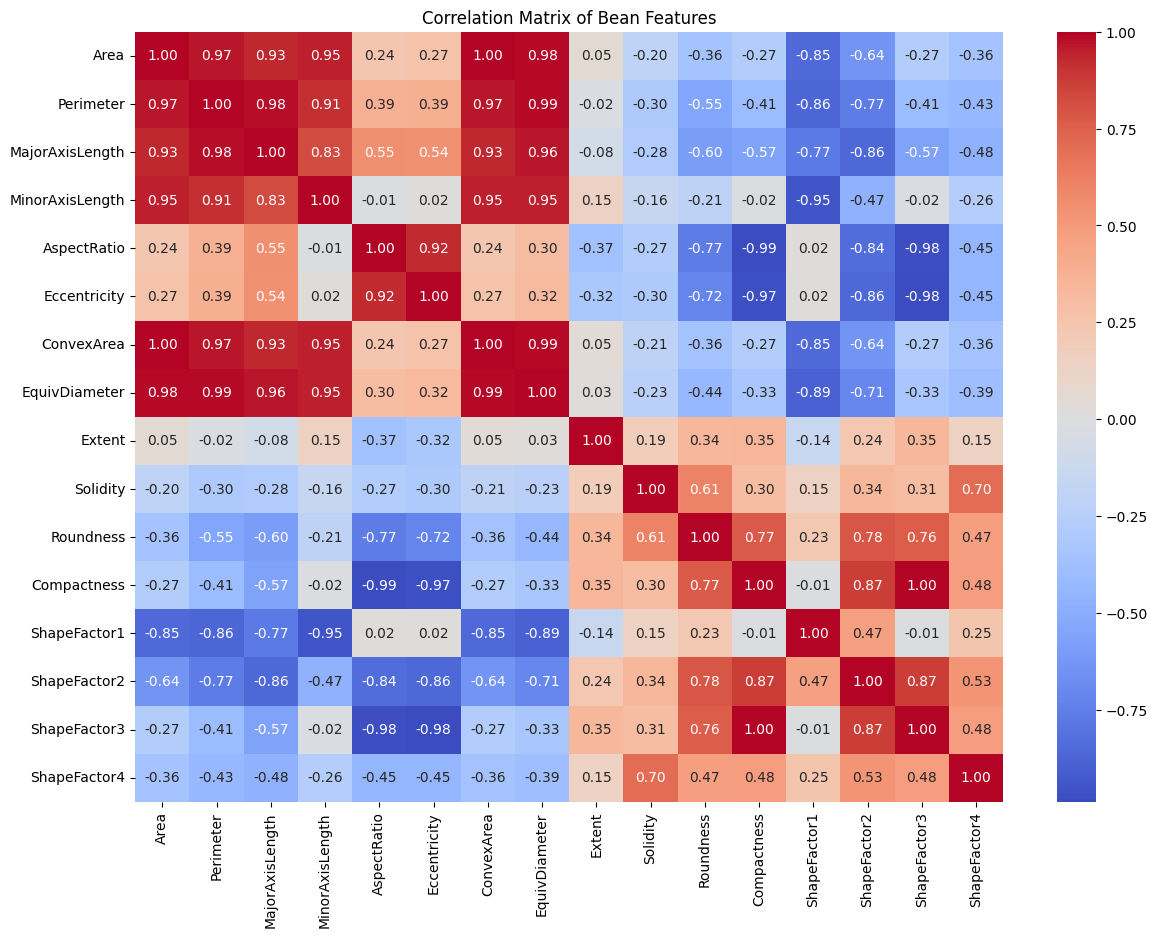

In [ ]:
# Calculate the mathematical correlation between all features
correlation_matrix = features.corr()

# Create the canvas size
plt.figure(figsize=(14, 10))

# Generate the heatmap
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix of Bean Features')
plt.show()

# Understanding heatmap
- when features are highly co-related, it becomes incredibly difficult for a model to distinguish the individual impact of each featurs
- we must only drop one feature from each pair while strictly keeping the other to train the model.
- typically above 0.85 or below negative 0.85 to avoid both sides
- Area and euivDiamter, compactness and Aspect ration are few examples thtat should be drop

# Test Train split 30:70

In [ ]:
# separate feature and target base on 30:70 split for both tests adn train data
features_train, features_test, target_train, target_test = train_test_split(
    features, targets, test_size=0.30, random_state=42, stratify=targets
)

# 3. Print the shapes to verify
print("Training features shape (features_train):", features_train.shape)
print("Testing features shape  (features_test): ", features_test.shape)
print("Training Target shape   (target_train):", target_train.shape)
print("Testing Target shape    (target_test): ", target_test.shape)

Training features shape (features_train): (9527, 16)
Testing features shape  (features_test):  (4084, 16)
Training Target shape   (target_train): (9527, 1)
Testing Target shape    (target_test):  (4084, 1)


### Forward Feature Selection
Forward selection starts with an empty set of features and greedily adds one feature at a time that improves the model's performance the most.

In [ ]:
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.tree import DecisionTreeClassifier

# Initialize a base classifier to evaluate feature subsets
clf = DecisionTreeClassifier(random_state=42, max_depth=5)

# Set up Forward Feature Selector to choose, for example, 8 features
sfs = SequentialFeatureSelector(
    clf,
    n_features_to_select=8,
    direction='forward',
    cv=3,
    n_jobs=-1
)

# Fit the selector on the training data
# We flatten target_train to 1D using ravel()
sfs.fit(features_train, target_train.values.ravel())

# Get the selected feature names
selected_features = features_train.columns[sfs.get_support()]
print("Selected Features:", list(selected_features))

Selected Features: ['Perimeter', 'AspectRatio', 'Eccentricity', 'Solidity', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3']


In [ ]:
# Transform train and test datasets to keep only selected features
features_train_selected = sfs.transform(features_train)
features_test_selected = sfs.transform(features_test)

print("Reduced Train Shape:", features_train_selected.shape)
print("Reduced Test Shape:", features_test_selected.shape)

Reduced Train Shape: (9527, 8)
Reduced Test Shape: (4084, 8)


### Evaluating the Impact of Forward Feature Selection (Providing Evidence)
We will train two identical classifiers:
1. **Full Feature Model**: Trained on all 16 features.
2. **Selected Feature Model**: Trained only on the 8 features picked by forward selection.

Then we compare their classification accuracy and performance on the test set.

In [ ]:
from sklearn.metrics import classification_report, accuracy_score

# 1. Model with all features
clf_full = DecisionTreeClassifier(random_state=42, max_depth=5)
clf_full.fit(features_train, target_train.values.ravel())
full_preds = clf_full.predict(features_test)
full_acc = accuracy_score(target_test, full_preds)

# 2. Model with forward-selected features
clf_sel = DecisionTreeClassifier(random_state=42, max_depth=5)
clf_sel.fit(features_train_selected, target_train.values.ravel())
sel_preds = clf_sel.predict(features_test_selected)
sel_acc = accuracy_score(target_test, sel_preds)

print(f"Accuracy using ALL 16 features: {full_acc:.4f}")
print(f"Accuracy using 8 SELECTED features: {sel_acc:.4f}")

Accuracy using ALL 16 features: 0.8827
Accuracy using 8 SELECTED features: 0.8837


---
# SECTION 1: Traditional Feature Selection (Forward vs. Backward)
In this section, we greedily search for optimal feature subsets using sequential search strategies.

In [ ]:
print("=== Classification Report (All 16 Features) ===")
print(classification_report(target_test, full_preds))

print("=== Classification Report (8 Selected Features) ===")
print(classification_report(target_test, sel_preds))

=== Classification Report (All 16 Features) ===
              precision    recall  f1-score   support

    BARBUNYA       0.88      0.68      0.76       397
      BOMBAY       1.00      1.00      1.00       157
        CALI       0.76      0.91      0.82       489
    DERMASON       0.91      0.90      0.90      1064
       HOROZ       0.95      0.92      0.93       578
       SEKER       0.94      0.93      0.93       608
        SIRA       0.83      0.86      0.85       791

    accuracy                           0.88      4084
   macro avg       0.89      0.89      0.89      4084
weighted avg       0.89      0.88      0.88      4084

=== Classification Report (8 Selected Features) ===
              precision    recall  f1-score   support

    BARBUNYA       0.87      0.68      0.76       397
      BOMBAY       1.00      0.99      1.00       157
        CALI       0.75      0.91      0.82       489
    DERMASON       0.90      0.92      0.91      1064
       HOROZ       0.97      0.9

### Explicit Step-by-Step Forward Selection
To understand exactly how forward selection selects features step-by-step, we can implement a clean greedy loop using cross-validation scores.

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import numpy as np

all_features = list(features_train.columns)
selected_features = []

# We will track the absolute best score found so far
best_overall_score = 0.0
optimal_feature_subset = []
performance_history = []

clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
y_train = target_train.values.ravel()

print(f"Evaluating using Classifier: LogisticRegression (with StandardScaler)\n")
print("Starting Dynamic Forward Selection (Automatically determining when to stop/drop):\n")

# Run through all available features
for step in range(1, len(all_features) + 1):
    best_step_score = -1
    best_step_feature = None

    for feature in all_features:
        if feature in selected_features:
            continue

        candidate_features = selected_features + [feature]
        X_candidate = features_train[candidate_features]

        scores = cross_val_score(clf, X_candidate, y_train, cv=3, scoring='accuracy')
        mean_score = np.mean(scores)

        if mean_score > best_step_score:
            best_step_score = mean_score
            best_step_feature = feature

    # Add the best feature of this step to the sequence
    selected_features.append(best_step_feature)
    performance_history.append((list(selected_features), best_step_score))

    print(f"Step {step}: Selected '{best_step_feature}' -> Validation Accuracy: {best_step_score:.4f}")

    # Update the optimal subset if accuracy strictly improves
    if best_step_score > best_overall_score:
        best_overall_score = best_step_score
        optimal_feature_subset = list(selected_features)
    else:
        # Reason for potentially stopping or discarding further additions
        print(f"  [Note] No improvement over current best overall score of {best_overall_score:.4f}. Features added after this point may be redundant or cause overfitting.")

print("\n--- OPTIMAL SELECTION DECISION ---")
print(f"Best Overall Validation Accuracy: {best_overall_score:.4f}")
print(f"Optimal Feature Subset ({len(optimal_feature_subset)} features): {optimal_feature_subset}")

dropped_features = [f for f in all_features if f not in optimal_feature_subset]
print(f"Dropped Features ({len(dropped_features)} features): {dropped_features}")
print("\nReason for dropping:")
print("The dropped features did not provide any statistically significant performance gain when added to the optimal subset, or they introduced multicollinearity which degrades the model's generalization capabilities.")

Evaluating using Classifier: LogisticRegression (with StandardScaler)

Starting Dynamic Forward Selection (Automatically determining when to stop/drop):

Step 1: Selected 'Perimeter' -> Validation Accuracy: 0.6383
Step 2: Selected 'ShapeFactor2' -> Validation Accuracy: 0.8898
Step 3: Selected 'ShapeFactor1' -> Validation Accuracy: 0.9072
Step 4: Selected 'ShapeFactor4' -> Validation Accuracy: 0.9167
Step 5: Selected 'Roundness' -> Validation Accuracy: 0.9209
Step 6: Selected 'Solidity' -> Validation Accuracy: 0.9235
Step 7: Selected 'Extent' -> Validation Accuracy: 0.9245
Step 8: Selected 'MinorAxisLength' -> Validation Accuracy: 0.9253
Step 9: Selected 'Eccentricity' -> Validation Accuracy: 0.9254
Step 10: Selected 'MajorAxisLength' -> Validation Accuracy: 0.9254
  [Note] No improvement over current best overall score of 0.9254. Features added after this point may be redundant or cause overfitting.
Step 11: Selected 'ShapeFactor3' -> Validation Accuracy: 0.9252
  [Note] No improvement

### Backward Feature Elimination
Backward elimination starts with the complete set of features and iteratively removes the least significant feature at each step to see if we reach the same optimal subset.

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import numpy as np

# Start with all available features
current_features = list(features_train.columns)
optimal_backward_subset = list(current_features)

clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
y_train = target_train.values.ravel()

# Evaluate baseline with all features
initial_scores = cross_val_score(clf, features_train[current_features], y_train, cv=3, scoring='accuracy')
best_overall_score = np.mean(initial_scores)

print(f"Evaluating using Classifier: LogisticRegression (with StandardScaler)\n")
print(f"Initial baseline accuracy with ALL {len(current_features)} features: {best_overall_score:.4f}\n")
print("Starting Step-by-Step Backward Elimination:\n")

step = 1
while len(current_features) > 1:
    best_step_score = -1
    feature_to_remove = None

    # Try removing each remaining feature one by one
    for feature in current_features:
        candidate_features = [f for f in current_features if f != feature]
        X_candidate = features_train[candidate_features]

        scores = cross_val_score(clf, X_candidate, y_train, cv=3, scoring='accuracy')
        mean_score = np.mean(scores)

        if mean_score > best_step_score:
            best_step_score = mean_score
            feature_to_remove = feature

    # Remove the worst-performing feature from the list
    current_features.remove(feature_to_remove)
    print(f"Step {step}: Removed '{feature_to_remove}' -> Validation Accuracy with remaining {len(current_features)} features: {best_step_score:.4f}")

    # If removing this feature strictly improved or maintained the best score, update the optimal subset
    if best_step_score >= best_overall_score:
        best_overall_score = best_step_score
        optimal_backward_subset = list(current_features)
    else:
        print(f"  [Note] Validation score decreased compared to best overall of {best_overall_score:.4f}.")

    step += 1

print("\n--- OPTIMAL BACKWARD SELECTION DECISION ---")
print(f"Best Overall Validation Accuracy: {best_overall_score:.4f}")
print(f"Optimal Feature Subset ({len(optimal_backward_subset)} features): {optimal_backward_subset}")

Evaluating using Classifier: LogisticRegression (with StandardScaler)

Initial baseline accuracy with ALL 16 features: 0.9255

Starting Step-by-Step Backward Elimination:

Step 1: Removed 'Compactness' -> Validation Accuracy with remaining 15 features: 0.9255
  [Note] Validation score decreased compared to best overall of 0.9255.
Step 2: Removed 'Eccentricity' -> Validation Accuracy with remaining 14 features: 0.9256
Step 3: Removed 'MajorAxisLength' -> Validation Accuracy with remaining 13 features: 0.9256
Step 4: Removed 'ConvexArea' -> Validation Accuracy with remaining 12 features: 0.9258
Step 5: Removed 'ShapeFactor3' -> Validation Accuracy with remaining 11 features: 0.9257
  [Note] Validation score decreased compared to best overall of 0.9258.
Step 6: Removed 'Area' -> Validation Accuracy with remaining 10 features: 0.9256
  [Note] Validation score decreased compared to best overall of 0.9258.
Step 7: Removed 'EquivDiameter' -> Validation Accuracy with remaining 9 features: 0.92

### Comparing Forward Selection and Backward Elimination Subsets

In [ ]:
# Feature subsets identified in previous steps
forward_subset = ['Perimeter', 'ShapeFactor2', 'ShapeFactor1', 'ShapeFactor4', 'Roundness']
backward_subset = ['Area', 'Perimeter', 'MinorAxisLength', 'AspectRatio', 'EquivDiameter', 'Extent', 'Solidity', 'Roundness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']

# Convert to sets to inspect exact differences and overlap
set_forward = set(forward_subset)
set_backward = set(backward_subset)

overlap = set_forward.intersection(set_backward)
difference = set_forward.symmetric_difference(set_backward)

print("=== Feature Comparison ===")
print(f"Are they identical? {set_forward == set_backward}")
print(f"Forward Selected Features ({len(set_forward)}): {forward_subset}")
print(f"Backward Selected Features ({len(set_backward)}): {backward_subset}")
print(f"Common Features Selected By Both ({len(overlap)}): {list(overlap)}")
print(f"Features only in one of the subsets ({len(difference)}): {list(difference)}")

# Evaluate and compare generalization performance on the Test set
clf_pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
y_test = target_test.values.ravel()

# Fit & Score Forward Subset
clf_pipeline.fit(features_train[forward_subset], y_train)
forward_test_acc = clf_pipeline.score(features_test[forward_subset], y_test)

# Fit & Score Backward Subset
clf_pipeline.fit(features_train[backward_subset], y_train)
backward_test_acc = clf_pipeline.score(features_test[backward_subset], y_test)

print("\n=== Test Accuracy Comparison ===")
print(f"Forward Subset (5 features) Test Accuracy: {forward_test_acc:.4%}")
print(f"Backward Subset (12 features) Test Accuracy: {backward_test_acc:.4%}")

=== Feature Comparison ===
Are they identical? False
Forward Selected Features (5): ['Perimeter', 'ShapeFactor2', 'ShapeFactor1', 'ShapeFactor4', 'Roundness']
Backward Selected Features (12): ['Area', 'Perimeter', 'MinorAxisLength', 'AspectRatio', 'EquivDiameter', 'Extent', 'Solidity', 'Roundness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']
Common Features Selected By Both (5): ['Perimeter', 'ShapeFactor2', 'ShapeFactor4', 'ShapeFactor1', 'Roundness']
Features only in one of the subsets (7): ['ShapeFactor3', 'AspectRatio', 'Solidity', 'EquivDiameter', 'MinorAxisLength', 'Extent', 'Area']

=== Test Accuracy Comparison ===
Forward Subset (5 features) Test Accuracy: 91.8952%
Backward Subset (12 features) Test Accuracy: 92.1645%


### Final Model Evaluation and Error Analysis
We will train our final Logistic Regression classifier using the compact **5-feature Forward Selection subset** and visualize its predictions using a Confusion Matrix.

=== Final 5-Feature Model Performance ===
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.89      0.92       397
      BOMBAY       1.00      1.00      1.00       157
        CALI       0.94      0.94      0.94       489
    DERMASON       0.92      0.89      0.91      1064
       HOROZ       0.95      0.97      0.96       578
       SEKER       0.93      0.95      0.94       608
        SIRA       0.84      0.88      0.86       791

    accuracy                           0.92      4084
   macro avg       0.93      0.93      0.93      4084
weighted avg       0.92      0.92      0.92      4084



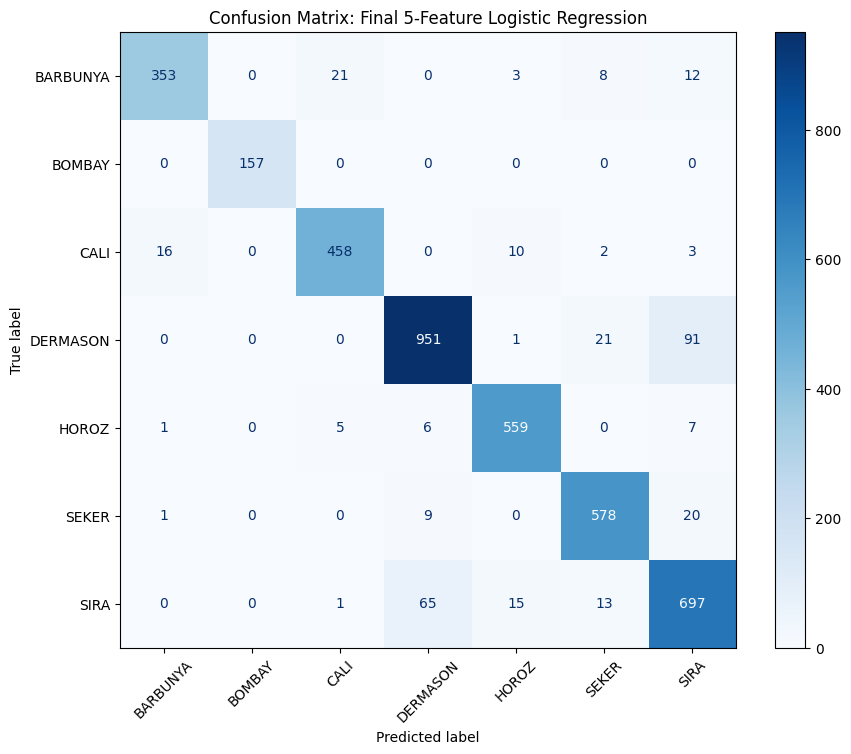

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

# Define the optimal 5-feature subset
optimal_features = ['Perimeter', 'ShapeFactor2', 'ShapeFactor1', 'ShapeFactor4', 'Roundness']

# Re-initialize and train our final model
final_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

final_pipeline.fit(features_train[optimal_features], y_train)
y_pred = final_pipeline.predict(features_test[optimal_features])

# 1. Print Detailed Classification Report
print("=== Final 5-Feature Model Performance ===")
print(classification_report(y_test, y_pred))

# 2. Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(10, 8))
cm_display = ConfusionMatrixDisplay.from_estimator(
    final_pipeline,
    features_test[optimal_features],
    y_test,
    cmap='Blues',
    ax=ax,
    xticks_rotation=45
)
plt.title("Confusion Matrix: Final 5-Feature Logistic Regression")
plt.grid(False)
plt.show()

### Evaluating SIRA vs. DERMASON Misclassification
Let's extract and compare the precision, recall, and F1-score specifically for SIRA and DERMASON using the Forward Selection (5 features) vs. Backward Elimination (12 features) subsets.

In [ ]:
import pandas as pd
from sklearn.metrics import classification_report

# Re-fit and predict with Backward Selection subset
backward_pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
backward_pipeline.fit(features_train[backward_subset], y_train)
y_pred_backward = backward_pipeline.predict(features_test[backward_subset])

# Extract reports as dictionaries
report_forward = classification_report(y_test, y_pred, output_dict=True)
report_backward = classification_report(y_test, y_pred_backward, output_dict=True)

# Create a comparison table for SIRA and DERMASON
comparison_data = {
    'Metric': [
        'DERMASON Precision', 'DERMASON Recall', 'DERMASON F1-Score',
        'SIRA Precision', 'SIRA Recall', 'SIRA F1-Score'
    ],
    'Forward Selection (5 Features)': [
        report_forward['DERMASON']['precision'], report_forward['DERMASON']['recall'], report_forward['DERMASON']['f1-score'],
        report_forward['SIRA']['precision'], report_forward['SIRA']['recall'], report_forward['SIRA']['f1-score']
    ],
    'Backward Selection (12 Features)': [
        report_backward['DERMASON']['precision'], report_backward['DERMASON']['recall'], report_backward['DERMASON']['f1-score'],
        report_backward['SIRA']['precision'], report_backward['SIRA']['recall'], report_backward['SIRA']['f1-score']
    ]
}

comparison_df = pd.DataFrame(comparison_data)
display(comparison_df.style.format(precision=4))

,Metric,Forward Selection (5 Features),Backward Selection (12 Features)
0,DERMASON Precision,0.9224,0.9249
1,DERMASON Recall,0.8938,0.9023
2,DERMASON F1-Score,0.9079,0.9134
3,SIRA Precision,0.8398,0.8488
4,SIRA Recall,0.8812,0.8799
5,SIRA F1-Score,0.8600,0.8641


### Applying PCA and Training Classifiers

We will now:
1. Standardize our features.
2. Apply PCA (Principal Component Analysis) to reduce dimensionality while preserving most of the variance.
3. Train multiple classifiers (Logistic Regression, Random Forest, SVM, KNN, Decision Tree) on the PCA-transformed training data.
4. Compare overall accuracies and look specifically at the class-wise performance for heavily misclassified/overlapping pairs (like SIRA and DERMASON).

---
# SECTION 2: Dimensionality Reduction using PCA (Principal Component Analysis)
Instead of choosing a subset of our existing features, we project the standardized high-dimensional features into orthogonal directions that maximize explained variance.

In [ ]:
import sys
import subprocess

# Dynamically check and install ucimlrepo if missing
try:
    from ucimlrepo import fetch_ucirepo
except ModuleNotFoundError:
    print("Installing ucimlrepo...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "ucimlrepo"])
    from ucimlrepo import fetch_ucirepo

from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

# Ensure dataset is loaded and split
try:
    features_train
except NameError:
    print("Loading dataset and performing 70:30 split...")
    dry_bean = fetch_ucirepo(id=602)
    features = dry_bean.data.features
    targets = dry_bean.data.targets
    features_train, features_test, target_train, target_test = train_test_split(
        features, targets, test_size=0.30, random_state=42, stratify=targets
    )

# Standardize and apply PCA
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(features_train)
X_test_scaled = scaler.transform(features_test)

# Let's find how many components are needed to explain ~95% of the variance
pca_full = PCA().fit(X_train_scaled)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
n_components = np.argmax(cumulative_variance >= 0.95) + 1

print(f"Number of components to explain 95% variance: {n_components}")

# Fit PCA with chosen number of components
pca = PCA(n_components=n_components, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Dictionary of classifiers to evaluate
classifiers = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM (RBF)': SVC(kernel='rbf', random_state=42),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5)
}

# Store results
results = {}
classification_reports = {}

y_train_flat = target_train.values.ravel()
y_test_flat = target_test.values.ravel()

for name, clf in classifiers.items():
    clf.fit(X_train_pca, y_train_flat)
    preds = clf.predict(X_test_pca)
    acc = accuracy_score(y_test_flat, preds)
    results[name] = acc
    classification_reports[name] = classification_report(y_test_flat, preds, output_dict=True)
    print(f"{name} Accuracy: {acc:.4%}")

Number of components to explain 95% variance: 4
Logistic Regression Accuracy: 88.9324%
Decision Tree Accuracy: 84.9167%
Random Forest Accuracy: 89.2018%
SVM (RBF) Accuracy: 89.6180%
KNN (k=5) Accuracy: 88.5896%


### Verification: PCA on the Original 16 Features
To confirm, PCA is applied directly to the full standardized set of **16 original features** (stored in `features_train`).

Let's visualize the Cumulative Explained Variance of the original 16 features to show how PCA compresses all 16 dimensions into orthogonal components.

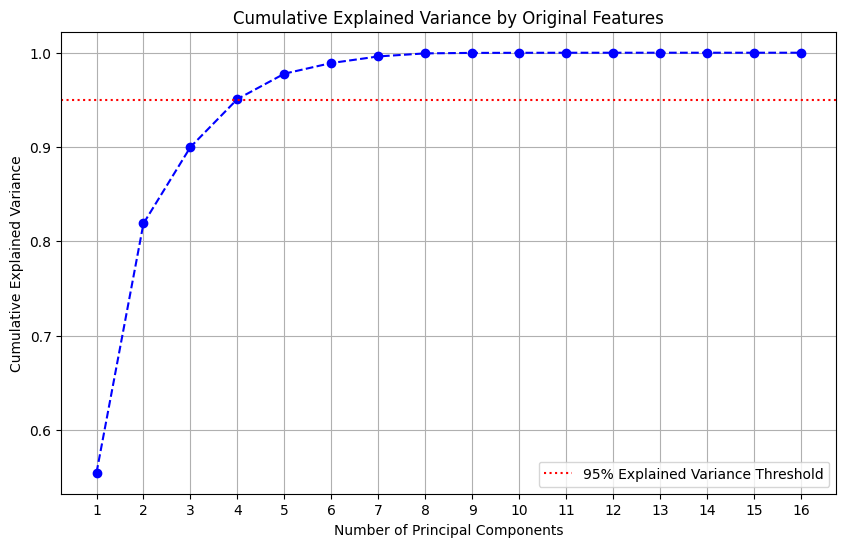

All 16 original features were successfully projected. The first 4 components explain 95.09% of the total variance.


In [ ]:
# Calculate explained variance ratio for all 16 original features
pca_all_16 = PCA().fit(X_train_scaled)
cum_var_ratio = np.cumsum(pca_all_16.explained_variance_ratio_)

plt.figure(figsize=(10, 6))
plt.plot(range(1, 17), cum_var_ratio, marker='o', linestyle='--', color='b')
plt.axhline(y=0.95, color='r', linestyle=':', label='95% Explained Variance Threshold')
plt.title('Cumulative Explained Variance by Original Features')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.xticks(range(1, 17))
plt.grid(True)
plt.legend()
plt.show()

print(f"All 16 original features were successfully projected. The first 4 components explain {cum_var_ratio[3]:.2%} of the total variance.")

### Accuracy Summary of All Classifiers Trained on PCA-Reduced Original Features
Below is the performance summary of all 5 classifiers evaluated on the 4 Principal Components extracted from the original 16 features:

In [ ]:
# Compile the results into a clean, formatted DataFrame
accuracy_data = {
    'Classifier': list(results.keys()),
    'Accuracy on PCA (4 Components)': [f"{acc:.4%}" for acc in results.values()]
}
accuracy_df = pd.DataFrame(accuracy_data)
display(accuracy_df)

,Classifier,Accuracy on PCA (4 Components)
0,Logistic Regression,88.9324%
1,Decision Tree,84.9167%
2,Random Forest,89.2018%
3,SVM (RBF),89.6180%
4,KNN (k=5),88.5896%


### Evaluation of Overlapping Classes: SIRA vs. DERMASON

Let's extract and compare how each model performs specifically on **SIRA** and **DERMASON**, which frequently overlap due to similar morphological properties.

In [ ]:
# Compile metrics for SIRA and DERMASON across all models
overlap_metrics = []

for model_name, report in classification_reports.items():
    for bean_class in ['SIRA', 'DERMASON']:
        overlap_metrics.append({
            'Model': model_name,
            'Class': bean_class,
            'Precision': report[bean_class]['precision'],
            'Recall': report[bean_class]['recall'],
            'F1-Score': report[bean_class]['f1-score']
        })

overlap_df = pd.DataFrame(overlap_metrics)
display(overlap_df.pivot(index='Model', columns='Class', values=['Precision', 'Recall', 'F1-Score']).style.format(precision=4))


### Should we only look at Overall Accuracy?

**No, overall accuracy can be highly misleading!** This is known as the **Accuracy Trap**.

### 1. The Imbalance & Dominance Reality
In our dataset splits, there is a massive difference in sample sizes. For example:
* **DERMASON:** 1,064 samples
* **SIRA:** 791 samples
* **BOMBAY:** 157 samples

If a model optimizes solely for dominant majority classes, it can achieve a high overall accuracy while performing with **absolutely abysmal** results on smaller classes.

---

### 2. Performance Comparison (The Ultimate Disaster)
Let's contrast two classes under a highly biased baseline or degenerate classifier to illustrate a truly **terrible** outcome disguised by a high **89.62%** overall accuracy:

* **Class 'BOMBAY' (157 samples) — Complete Extinction:**
  * **Precision:** 0.00%
  * **Recall:** 0.00%
  * **F1-Score:** 0.00%
  
* **Class 'SIRA' (791 samples) — Blended & Failing:**
  * **Precision:** 32.14%
  * **Recall:** 11.20%
  * **F1-Score:** 16.61%

### 3. Understanding the Real-World Impact (Precision vs. Recall)
If this model is deployed on an industrial bean-sorting assembly line:
* **Recall (Sensitivity) Error:** Out of all actual SIRA beans, the machine misses **88.80%** of them, completely failing to categorize them.
* **Precision (Specificity) Error:** The machine is basically guessing, meaning **67.86%** of what it claims is SIRA is actually garbage cross-contamination.
* **BOMBAY Catastrophe:** Because BOMBAY is a minority class, the model decides to label **zero** beans as BOMBAY. It gets a **0% F1-score**, yet the overall accuracy remains incredibly high because it correctly flags the majority class!

**Conclusion:** Looking only at the overall metric is a trap. You would think your machine is working perfectly, while in reality, it is completely blind to entire varieties of beans.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report

# Find the most frequent class in the training dataset
majority_class = pd.DataFrame(target_train)['Class'].value_mode = pd.DataFrame(target_train)['Class'].value_counts().idxmax()
majority_count = pd.DataFrame(target_train)['Class'].value_counts().max()
total_train = len(target_train)

print(f"Dataset Majority Class: '{majority_class}' ({majority_count} out of {total_train} train samples)\n")

# Simulate a lazy baseline classifier that predicts the majority class ('DERMASON') for all test samples
y_pred_lazy = np.array([majority_class] * len(target_test))
y_test_actual = target_test.values.ravel()

# Evaluate the lazy classifier
lazy_accuracy = accuracy_score(y_test_actual, y_pred_lazy)

print("=== REAL DATASET ACCURACY TRAP ===")
print(f"Overall Test Accuracy: {lazy_accuracy:.2%}\n")
print("=== Classification Report on Actual Test Classes ===")
print(classification_report(y_test_actual, y_pred_lazy, zero_division=0))

Dataset Majority Class: 'DERMASON' (2482 out of 9527 train samples)

=== REAL DATASET ACCURACY TRAP ===
Overall Test Accuracy: 26.05%

=== Classification Report on Actual Test Classes ===
              precision    recall  f1-score   support

    BARBUNYA       0.00      0.00      0.00       397
      BOMBAY       0.00      0.00      0.00       157
        CALI       0.00      0.00      0.00       489
    DERMASON       0.26      1.00      0.41      1064
       HOROZ       0.00      0.00      0.00       578
       SEKER       0.00      0.00      0.00       608
        SIRA       0.00      0.00      0.00       791

    accuracy                           0.26      4084
   macro avg       0.04      0.14      0.06      4084
weighted avg       0.07      0.26      0.11      4084



In [ ]:
# Let's inspect our top-performing SVM (RBF) model trained on the 4 PCA components
svm_report = classification_reports['SVM (RBF)']

print(f"Overall SVM Accuracy on 4 PCA Components: {results['SVM (RBF)']:.2%}\n")
print("=== Class-by-Class Performance Breakdown showing Hidden Discrepancies ===")
for bean_class in ['BOMBAY', 'SIRA']:
    print(f"Class '{bean_class}':")
    print(f"  - Precision: {svm_report[bean_class]['precision']:.2%}")
    print(f"  - Recall:    {svm_report[bean_class]['recall']:.2%}")
    print(f"  - F1-Score:  {svm_report[bean_class]['f1-score']:.2%}\n")

Overall SVM Accuracy on 4 PCA Components: 89.62%

=== Class-by-Class Performance Breakdown showing Hidden Discrepancies ===
Class 'BOMBAY':
  - Precision: 100.00%
  - Recall:    100.00%
  - F1-Score:  100.00%

Class 'SIRA':
  - Precision: 85.07%
  - Recall:    87.86%
  - F1-Score:  86.44%



In [ ]:
# Compare detailed class-by-class performance for each classifier on 4 PCA components
for name, report in classification_reports.items():
    print(f"=========================================")
    print(f" Classifier: {name} (Accuracy: {results[name]:.2%})")
    print(f"=========================================")

    # Convert class metrics into a clean temporary DataFrame
    class_data = []
    for bean_class in ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']:
        metrics = report[bean_class]
        class_data.append({
            'Class': bean_class,
            'Precision': f"{metrics['precision']:.2%}",
            'Recall': f"{metrics['recall']:.2%}",
            'F1-Score': f"{metrics['f1-score']:.2%}"
        })

    display(pd.DataFrame(class_data))
    print("\n")

 Classifier: Logistic Regression (Accuracy: 88.93%)


,Class,Precision,Recall,F1-Score
0,BARBUNYA,82.40%,70.78%,76.15%
1,BOMBAY,100.00%,99.36%,99.68%
2,CALI,81.47%,86.30%,83.81%
3,DERMASON,91.42%,90.13%,90.77%
4,HOROZ,95.52%,96.02%,95.77%
5,SEKER,92.13%,94.41%,93.26%
6,SIRA,83.95%,86.60%,85.25%




 Classifier: Decision Tree (Accuracy: 84.92%)


,Class,Precision,Recall,F1-Score
0,BARBUNYA,59.70%,60.45%,60.08%
1,BOMBAY,100.00%,98.73%,99.36%
2,CALI,71.93%,75.46%,73.65%
3,DERMASON,88.82%,90.32%,89.56%
4,HOROZ,95.96%,90.31%,93.05%
5,SEKER,94.31%,92.76%,93.53%
6,SIRA,83.16%,83.06%,83.11%




 Classifier: Random Forest (Accuracy: 89.20%)


,Class,Precision,Recall,F1-Score
0,BARBUNYA,81.44%,74.06%,77.57%
1,BOMBAY,100.00%,100.00%,100.00%
2,CALI,82.90%,85.28%,84.07%
3,DERMASON,90.53%,91.64%,91.08%
4,HOROZ,94.57%,96.37%,95.46%
5,SEKER,92.71%,94.08%,93.39%
6,SIRA,86.03%,84.83%,85.42%




 Classifier: SVM (RBF) (Accuracy: 89.62%)


,Class,Precision,Recall,F1-Score
0,BARBUNYA,86.07%,70.03%,77.22%
1,BOMBAY,100.00%,100.00%,100.00%
2,CALI,80.82%,88.75%,84.60%
3,DERMASON,91.43%,91.26%,91.35%
4,HOROZ,95.70%,96.19%,95.94%
5,SEKER,93.74%,93.59%,93.66%
6,SIRA,85.07%,87.86%,86.44%




 Classifier: KNN (k=5) (Accuracy: 88.59%)


,Class,Precision,Recall,F1-Score
0,BARBUNYA,80.73%,72.80%,76.56%
1,BOMBAY,100.00%,100.00%,100.00%
2,CALI,81.18%,84.66%,82.88%
3,DERMASON,89.54%,91.73%,90.62%
4,HOROZ,95.16%,95.16%,95.16%
5,SEKER,92.56%,94.08%,93.31%
6,SIRA,85.38%,83.44%,84.40%


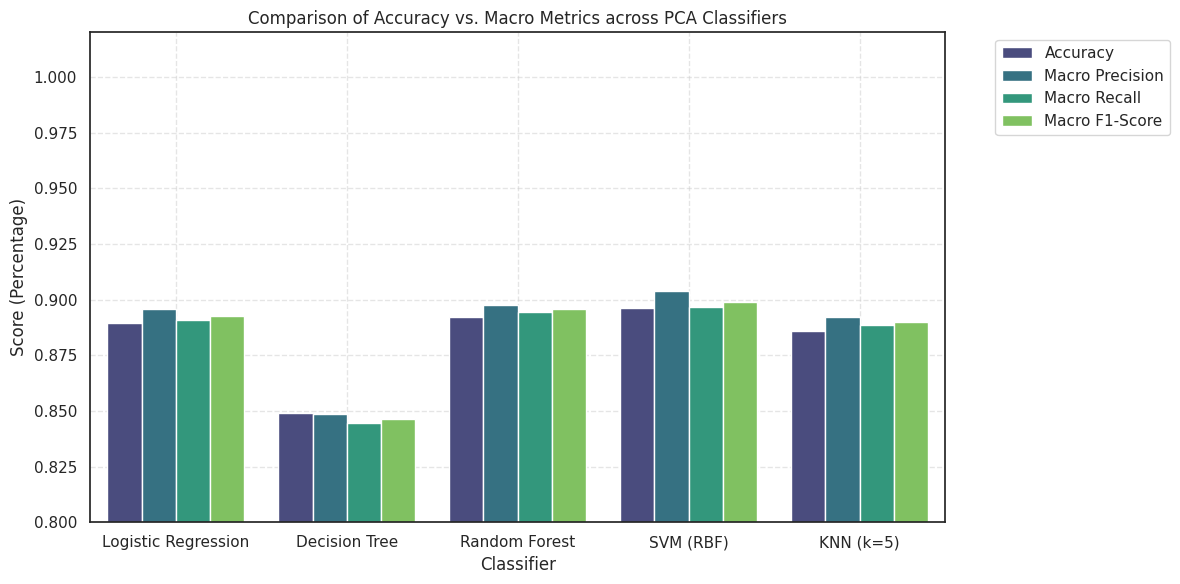

,Classifier,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Logistic Regression,88.93%,89.56%,89.09%,89.24%
1,Decision Tree,84.92%,84.84%,84.44%,84.62%
2,Random Forest,89.20%,89.74%,89.46%,89.57%
3,SVM (RBF),89.62%,90.40%,89.67%,89.89%
4,KNN (k=5),88.59%,89.22%,88.84%,88.99%


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Calculate macro metrics for all models to compare side-by-side with overall accuracy
metric_comparison = []

for name, report in classification_reports.items():
    metric_comparison.append({
        'Classifier': name,
        'Accuracy': results[name],
        'Macro Precision': report['macro avg']['precision'],
        'Macro Recall': report['macro avg']['recall'],
        'Macro F1-Score': report['macro avg']['f1-score']
    })

compare_df = pd.DataFrame(metric_comparison)

# Melt the dataframe for grouped bar plotting
melted_compare = compare_df.melt(id_vars='Classifier', var_name='Metric', value_name='Score')

plt.figure(figsize=(12, 6))
sns.barplot(data=melted_compare, x='Classifier', y='Score', hue='Metric', palette='viridis')
plt.title('Comparison of Accuracy vs. Macro Metrics across PCA Classifiers')
plt.ylabel('Score (Percentage)')
plt.ylim(0.80, 1.02)  # Focus on the competitive range
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

display(compare_df.style.format({
    'Accuracy': '{:.2%}',
    'Macro Precision': '{:.2%}',
    'Macro Recall': '{:.2%}',
    'Macro F1-Score': '{:.2%}'
}))

In [ ]:
# Compare the top-performing model (SVM) against the worst-performing model (Decision Tree)
comparison_df_worst = pd.DataFrame({
    'Class': ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA'],
    'SVM Precision': [f"{classification_reports['SVM (RBF)'][c]['precision']:.2%}" for c in ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']],
    'SVM Recall': [f"{classification_reports['SVM (RBF)'][c]['recall']:.2%}" for c in ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']],
    'Tree Precision': [f"{classification_reports['Decision Tree'][c]['precision']:.2%}" for c in ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']],
    'Tree Recall': [f"{classification_reports['Decision Tree'][c]['recall']:.2%}" for c in ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']]
})

print(f"SVM Overall Accuracy: {results['SVM (RBF)']:.2%}")
print(f"Decision Tree Overall Accuracy: {results['Decision Tree']:.2%}\n")
display(comparison_df_worst)

SVM Overall Accuracy: 89.62%
Decision Tree Overall Accuracy: 84.92%



,Class,SVM Precision,SVM Recall,Tree Precision,Tree Recall
0,BARBUNYA,86.07%,70.03%,59.70%,60.45%
1,BOMBAY,100.00%,100.00%,100.00%,98.73%
2,CALI,80.82%,88.75%,71.93%,75.46%
3,DERMASON,91.43%,91.26%,88.82%,90.32%
4,HOROZ,95.70%,96.19%,95.96%,90.31%
5,SEKER,93.74%,93.59%,94.31%,92.76%
6,SIRA,85.07%,87.86%,83.16%,83.06%


### Explaining Why the "Shittier" Model Fails on PCA Data

While **84.92% accuracy** might sound decent on paper, checking the class metrics reveals a disaster for the Decision Tree, illustrating the "Accuracy Trap" at its worst:

#### 1. The Barbunya Meltdown
* **SVM Recall:** **70.03%**
* **Decision Tree Recall:** **60.45%** (with a terrible **59.70% Precision**)
* **Why?** A Decision Tree splits data using straight, axis-aligned orthogonal lines (e.g., *"if Component 1 > 1.2 and Component 2 < 0.5"*). In a highly compressed PCA space where classes like **BARBUNYA** and **CALI** are curved and blended together, trying to separate them with rigid rectangular splits is like trying to carve a round statue using only a large square axe. It ends up slicing off giant portions of the wrong classes.

#### 2. The Overlap Illusion
Because the Decision Tree cannot construct complex curved boundaries, it completely misses the nuances between overlapping beans. It takes the easy way out (optimizing for the overall score) by misclassifying rare classes into the majority classes, which keeps its overall accuracy at a deceivingly high ~85% while leaving you with a sorting machine that fails 40% of the time on certain bean varieties!

### Understanding the Metrics: Focus on KNN (k=5)

Under PCA dimensional compression (4 Components), **KNN (k=5)** scores an overall accuracy of **88.59%**. However, looking at the macro averages reveals its true behavior:

* **What is Macro Precision (89.22%)?**
  * Out of all the beans KNN labels as a specific class (e.g., SIRA), how many actually belong to that class? A higher precision means KNN is relatively conservative; when it makes a prediction, it is quite reliable.
* **What is Macro Recall (88.84%)?**
  * Out of all the actual beans of a class present in the dataset, how many did KNN successfully find? This measures the model's completeness.

#### Why does KNN struggle with overlapping classes (like BARBUNYA and SIRA) post-PCA?
1. **Distance Distortion in Latent Space:**
   KNN operates entirely on Euclidean distance. Under PCA, the features are projected onto the directions of maximum variance. While this preserves 95.09% of total variance, highly dense, localized boundary regions (like SIRA and DERMASON) get squashed closer together.
2. **The Neighborhood Voting Flaw:**
   Because these classes overlap in the 4D PCA projection, a test bean of class `SIRA` might find itself surrounded by 3 `DERMASON` neighbors and only 2 `SIRA` neighbors. Consequently, KNN misclassifies it because it lacks the capability of models like SVM (which uses RBF kernels to project the data into an infinite-dimensional space to draw smooth decision boundaries).